# Zuber: what moves taxi rides in Chicago?

Zuber is a new ride-sharing company that is launching in Chicago. The goal of this project is to find patterns in the available data: which taxi companies are the biggest competitors, where the passengers are going, and if the weather changes the rides.

The project has four steps:

1. Import and web scraping
2. Data cleaning
3. Analysis
4. Hypothesis test

## Step 1. Import and web scraping

In [24]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats as st

#### Weather data from the website

The weather data for Chicago in November 2017 was in a table on a web page. It was collected with requests and BeautifulSoup in the script `01_web_scraping/weather_records.py`, which saves the table as a CSV file. Here the file is only read.

In [25]:
weather_records = pd.read_csv('../data/weather_records.csv')
weather_records.head()

,Date and time,Temperature,Description
0,2017-11-01 00:00:00,276.15,broken clouds
1,2017-11-01 01:00:00,275.70,scattered clouds
2,2017-11-01 02:00:00,275.61,overcast clouds
3,2017-11-01 03:00:00,275.35,broken clouds
4,2017-11-01 04:00:00,275.24,broken clouds


#### Files from the SQL queries

The other three files are results of the SQL queries that are in the `02_sql` folder.

- `project_sql_result_01.csv`: the taxi companies and the number of rides of each one on November 15 and 16, 2017.
- `project_sql_result_04.csv`: the neighborhoods of Chicago and the average number of rides that ended in each one in November 2017.
- `project_sql_result_07.csv`: the Saturday rides from the Loop to O'Hare airport, with the weather at the start of the ride and the duration in seconds.

In [26]:
companies = pd.read_csv('../data/project_sql_result_01.csv')
neighborhoods = pd.read_csv('../data/project_sql_result_04.csv')
loop_ohare = pd.read_csv('../data/project_sql_result_07.csv', parse_dates=['start_ts'])

## Step 2. Data cleaning

These files are results of SQL queries, so they should already be clean. Still, the data types, the missing values and the duplicates of each one are checked below.

In [27]:
companies.info()
print('Duplicates:', companies.duplicated().sum())
companies.head()

<class 'pandas.DataFrame'>
RangeIndex: 64 entries, 0 to 63
Data columns (total 2 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   company_name  64 non-null     str  
 1   trips_amount  64 non-null     int64
dtypes: int64(1), str(1)
memory usage: 1.1 KB
Duplicates: 0


,company_name,trips_amount
0,Flash Cab,19558
1,Taxi Affiliation Services,11422
2,Medallion Leasin,10367
3,Yellow Cab,9888
4,Taxi Affiliation Service Yellow,9299


In [28]:
neighborhoods.info()
print('Duplicates:', neighborhoods.duplicated().sum())
neighborhoods.head()

<class 'pandas.DataFrame'>
RangeIndex: 94 entries, 0 to 93
Data columns (total 2 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   dropoff_location_name  94 non-null     str    
 1   average_trips          94 non-null     float64
dtypes: float64(1), str(1)
memory usage: 1.6 KB
Duplicates: 0


,dropoff_location_name,average_trips
0,Loop,10727.466667
1,River North,9523.666667
2,Streeterville,6664.666667
3,West Loop,5163.666667
4,O'Hare,2546.900000


In [29]:
loop_ohare.info()
print('Duplicates:', loop_ohare.duplicated().sum())
loop_ohare.head()

<class 'pandas.DataFrame'>
RangeIndex: 1068 entries, 0 to 1067
Data columns (total 3 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   start_ts            1068 non-null   datetime64[us]
 1   weather_conditions  1068 non-null   str           
 2   duration_seconds    1068 non-null   float64       
dtypes: datetime64[us](1), float64(1), str(1)
memory usage: 25.2 KB
Duplicates: 197


,start_ts,weather_conditions,duration_seconds
0,2017-11-25 16:00:00,Good,2410.0
1,2017-11-25 14:00:00,Good,1920.0
2,2017-11-25 12:00:00,Good,1543.0
3,2017-11-04 10:00:00,Good,2512.0
4,2017-11-11 07:00:00,Good,1440.0


In [30]:
print('Rides with a duration of zero seconds:', (loop_ohare['duration_seconds'] == 0).sum())
loop_ohare['duration_seconds'].describe()

Rides with a duration of zero seconds: 6


count    1068.000000
mean     2071.731273
std       769.461125
min         0.000000
25%      1438.250000
50%      1980.000000
75%      2580.000000
max      7440.000000
Name: duration_seconds, dtype: float64

Findings:

- There are no missing values in the three files.
- The data types are correct. The names are text, `trips_amount` is an integer, `average_trips` is a decimal number because it is an average, and `start_ts` was converted to datetime when the file was read.
- `companies` and `neighborhoods` have no duplicates.
- `loop_ohare` has 197 duplicated rows, but they were kept. The start time is rounded to the hour, so two different rides can have the same hour, the same weather and the same duration. They are not errors.
- 6 rides have a duration of zero seconds, which looks like an error in the record. They are less than 1% of the data and they do not change the result of the hypothesis test, so they were kept too.

So no cleaning is needed.

## Step 3. Analysis

#### 1. Where are people going?

In [31]:
top_10_neighborhoods = neighborhoods.sort_values(by='average_trips', ascending=False).head(10)
top_10_neighborhoods

,dropoff_location_name,average_trips
0,Loop,10727.466667
1,River North,9523.666667
2,Streeterville,6664.666667
3,West Loop,5163.666667
4,O'Hare,2546.900000
5,Lake View,2420.966667
6,Grant Park,2068.533333
7,Museum Campus,1510.000000
8,Gold Coast,1364.233333
9,Sheffield & DePaul,1259.766667


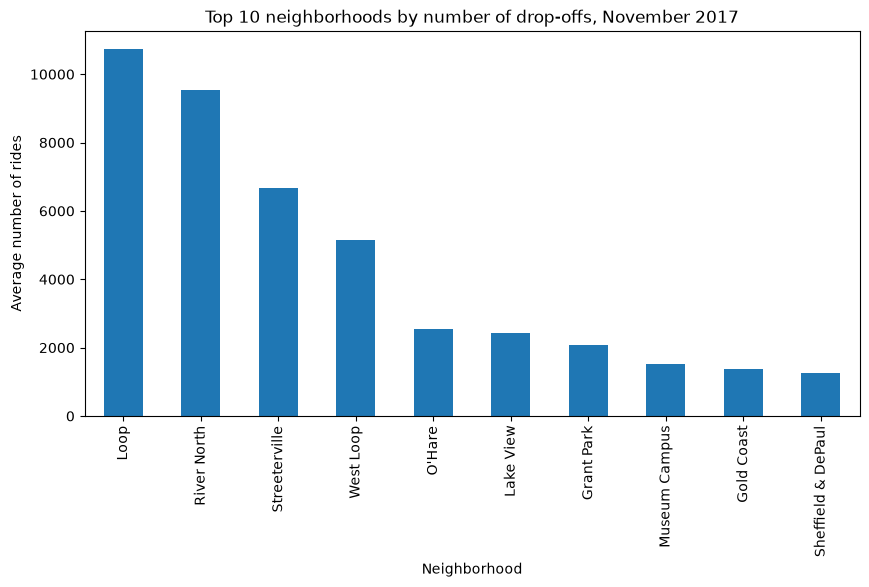

In [32]:
top_10_neighborhoods.plot(kind='bar', x='dropoff_location_name', y='average_trips', legend=False, figsize=(10, 5))
plt.title('Top 10 neighborhoods by number of drop-offs, November 2017')
plt.xlabel('Neighborhood')
plt.ylabel('Average number of rides')
plt.show()

In [33]:
# Share of all drop-offs
total_trips = neighborhoods['average_trips'].sum()
print(f"First 4 neighborhoods: {top_10_neighborhoods['average_trips'].head(4).sum() / total_trips:.0%}")
print(f"Top 10 neighborhoods: {top_10_neighborhoods['average_trips'].sum() / total_trips:.0%}")

First 4 neighborhoods: 57%
Top 10 neighborhoods: 77%


Most of the rides end downtown. The first four neighborhoods (Loop, River North, Streeterville and West Loop) are all in the central area, and together they have 57% of all the drop-offs. The top 10 has 77%.

O'Hare is in 5th place. It is the only one of the first five that is far from the center, which makes sense because it is the airport. This is also why the hypothesis test is about the rides from the Loop to O'Hare.

For Zuber, this shows that the launch does not need to cover the whole city in the same way. With enough cars in these few neighborhoods, the company already reaches most of the demand.

#### 2. Which taxi companies get the most rides?

In [34]:
print('Number of companies:', len(companies))
print('Companies with less than 100 rides:', (companies['trips_amount'] < 100).sum())

Number of companies: 64
Companies with less than 100 rides: 29


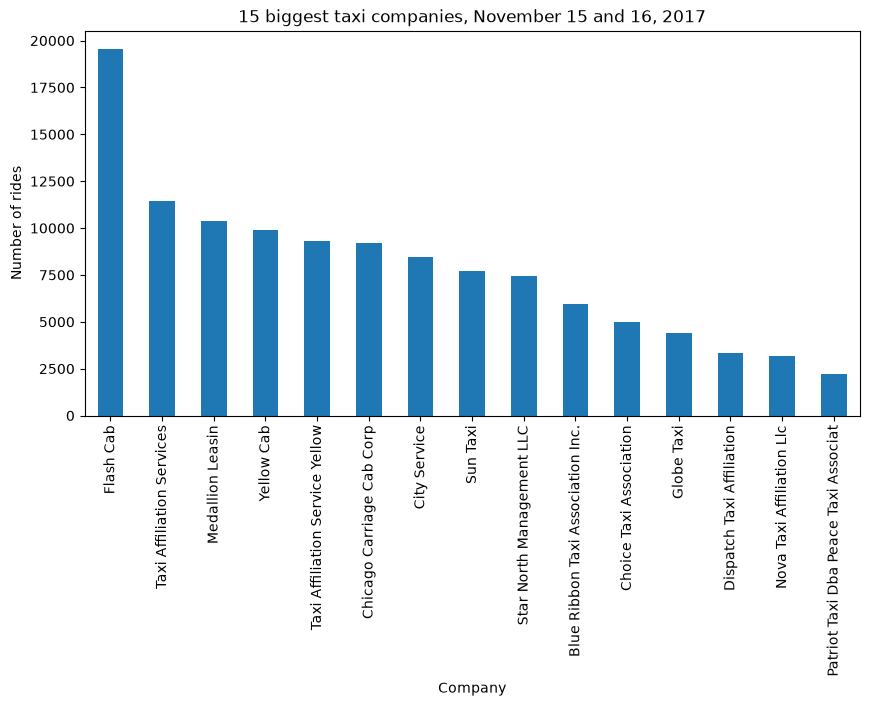

In [35]:
# 64 companies would make the chart unreadable, so only the 15 biggest are shown
top_15_companies = companies.sort_values(by='trips_amount', ascending=False).head(15)

top_15_companies.plot(kind='bar', x='company_name', y='trips_amount', legend=False, figsize=(10, 5))
plt.title('15 biggest taxi companies, November 15 and 16, 2017')
plt.xlabel('Company')
plt.ylabel('Number of rides')
plt.show()

In [36]:
print(f"Share of the 10 biggest companies: {top_15_companies['trips_amount'].head(10).sum() / companies['trips_amount'].sum():.0%}")

Share of the 10 biggest companies: 72%


The market has many companies, but only a few are really big. Flash Cab is the leader with 19,558 rides in two days, about 70% more than the second place, Taxi Affiliation Services, with 11,422. The 10 biggest companies have 72% of all the rides.

On the other side, 29 of the 64 companies had less than 100 rides in these two days. By the names, many of them look like individual drivers.

For Zuber, the real competition is a group of about ten companies, and Flash Cab is the main one.

#### 3. Do people ride less when the weather is bad?

This analysis uses the file with the Saturday rides from the Loop to O'Hare. The first step is to count the rides in each weather condition.

In [37]:
rides = loop_ohare.groupby('weather_conditions')['duration_seconds'].count()
print(rides)

weather_conditions
Bad     180
Good    888
Name: duration_seconds, dtype: int64


There are many more rides with good weather. But this comparison is not fair, because there were also many more hours of good weather than hours of rain on these Saturdays.

For a fair comparison, the number of rides is divided by the number of different hours each weather condition had. The result is how many rides happen in one hour, on average.

In [38]:
hours = loop_ohare.groupby('weather_conditions')['start_ts'].nunique()
print(hours)
print()

rides_per_hour = rides / hours
print(rides_per_hour)

weather_conditions
Bad     13
Good    68
Name: start_ts, dtype: int64

weather_conditions
Bad     13.846154
Good    13.058824
dtype: float64


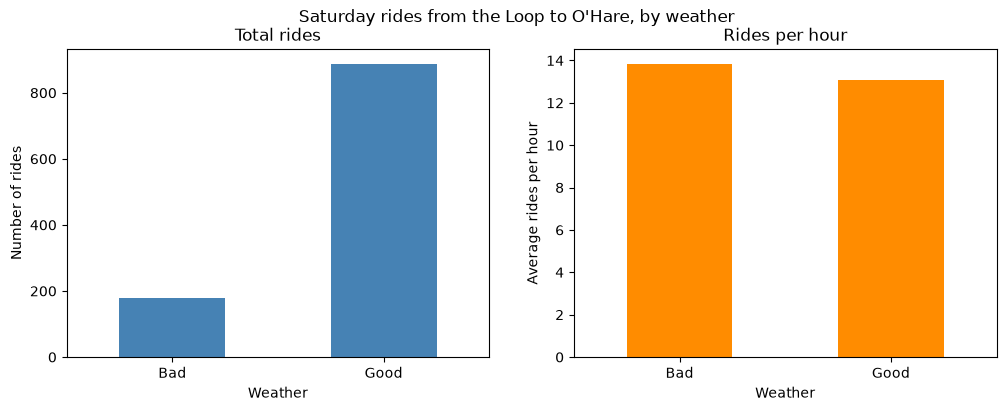

In [39]:
# Total rides and rides per hour, side by side
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

rides.plot(kind='bar', rot=0, ax=axes[0], color='steelblue')
axes[0].set_title('Total rides')
axes[0].set_xlabel('Weather')
axes[0].set_ylabel('Number of rides')

rides_per_hour.plot(kind='bar', rot=0, ax=axes[1], color='darkorange')
axes[1].set_title('Rides per hour')
axes[1].set_xlabel('Weather')
axes[1].set_ylabel('Average rides per hour')

plt.suptitle('Saturday rides from the Loop to O\'Hare, by weather')
plt.show()

In total there were 888 rides with good weather and only 180 with bad weather. But there were 68 hours of good weather and only 13 hours of bad weather.

Looking at one hour, the result is almost the same: about 13 rides per hour with good weather and about 14 with bad weather. So the rain does not make people ride less on this route. It makes sense, because the flight does not wait for the rain to stop.

This is only a simple comparison and not a statistical test, because there are only 13 hours of bad weather in the data.

## Step 4. Hypothesis test

The hypothesis to test is:

"The average duration of rides from the Loop to O'Hare International Airport changes on rainy Saturdays."

**How the hypotheses were formed**

- Null hypothesis (H0): the average duration of the rides is the same with good weather and with bad weather.
- Alternative hypothesis (H1): the average duration of the rides is different with good weather and with bad weather.

The null hypothesis always says that there is no difference, so "the same" is H0. The task asks if the duration changes and does not say if it gets longer or shorter, so the alternative hypothesis is only "different" and the test is two-sided.

**Which test was used and why**

The comparison is between the averages of two independent groups: the rides with good weather and the rides with bad weather. For this case the test is the t-test for two independent samples, `st.ttest_ind`.

This test has the `equal_var` parameter, which says if the two groups have similar variances or not. Levene's test is used first to decide it.

The significance level (alpha) is 0.05, the most common choice.

In [40]:
good_weather = loop_ohare[loop_ohare['weather_conditions'] == 'Good']['duration_seconds']
bad_weather = loop_ohare[loop_ohare['weather_conditions'] == 'Bad']['duration_seconds']

# Mean, variance and standard deviation of each group
print(f'Good weather: {len(good_weather)} rides | mean {good_weather.mean():.2f} | variance {good_weather.var():.2f} | std {good_weather.std():.2f}')
print(f'Bad weather: {len(bad_weather)} rides | mean {bad_weather.mean():.2f} | variance {bad_weather.var():.2f} | std {bad_weather.std():.2f}')

Good weather: 888 rides | mean 1999.68 | variance 576382.01 | std 759.20
Bad weather: 180 rides | mean 2427.21 | variance 520294.09 | std 721.31


In [41]:
alpha = 0.05

# Levene's test checks if the two groups have similar variances.
# p-value above alpha: similar variances, equal_var=True
# p-value below alpha: different variances, equal_var=False
levene_results = st.levene(good_weather, bad_weather)
print('Levene p-value:', levene_results.pvalue)

Levene p-value: 0.5332038671976089


In [42]:
# Levene's p-value is above alpha, so equal_var=True
results = st.ttest_ind(good_weather, bad_weather, equal_var=True)

print('The null hypothesis is that the average duration is the same with good and bad weather')
print('The alternative hypothesis is that the average duration is different with good and bad weather')
print('p-value:', results.pvalue)

if results.pvalue < alpha:
    print('We reject the null hypothesis')
else:
    print('We cannot reject the null hypothesis')

The null hypothesis is that the average duration is the same with good and bad weather
The alternative hypothesis is that the average duration is different with good and bad weather
p-value: 6.517970327099489e-12
We reject the null hypothesis


The p-value is much smaller than alpha (0.05), so the null hypothesis is rejected. The average duration of the rides from the Loop to O'Hare is different on rainy Saturdays.

Looking at the means, the ride takes about 2,427 seconds with bad weather (around 40 minutes) and about 2,000 seconds with good weather (around 33 minutes). So with rain the ride takes about 7 minutes more.

The variances of the two groups are close, and Levene's test confirmed it with a p-value of 0.53, so `equal_var=True` was the right choice.

It is also worth noting that the rain does not make people ride less on this route, because no one wants to miss their flight.

## Conclusion

- **Most of the rides end downtown.** Loop, River North, Streeterville and West Loop have 57% of all the drop-offs, and O'Hare airport is the main destination outside the center.
- **A few companies have most of the market.** There are 64 taxi companies, but the 10 biggest have 72% of the rides, and Flash Cab is the leader.
- **The rain does not reduce the rides to the airport, but it makes them longer.** On Saturdays the number of rides per hour from the Loop to O'Hare is almost the same with good or bad weather. But the hypothesis test showed that the average duration changes: with rain the ride takes about 7 minutes more.

For Zuber, this means the company can focus the launch on downtown and on the airport route, pay attention to a small group of big competitors, and be ready for rainy days, when each ride takes longer and the cars stay busy for more time.